# 03b — Follow-ups to Phase 3 (validation only)

1. **Within cell type x sample.** With a random split, cells of the same sample are in both training and
   validation. If ridge used sample/site signatures in RNA to predict the site-dependent protein
   background, its within-type correlation would drop once we also hold the sample fixed. This is
   compared with the own-gene result from Phase 2 (0.07 -> 0.06).
2. **Within-type Pearson by number of PCA components (50 ... 2,000).** Tests the hypothesis "PCA loses
   within-type information". Also shown with the within cell type x sample metric.
3. **Same cells for both metrics.** Repeats (1) using only cells in the type x sample groups that reach
   50 validation cells, so both columns are computed on exactly the same cells.
4. **donor1 only** (the one donor measured at all four sites): within type vs. within type x site. The
   donor is fixed, so the difference reflects the site effect.

The features are rebuilt exactly as in notebook 03 (train-only HVG/PCA, same split). Notebook 03's
validation predictions are reproduced first as a check. Test cells are never loaded.

In [1]:
import os, sys, time, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from citeseq.paths import RESULTS_DIR, FIGURES_DIR, PROCESSED_DIR
from citeseq.data_prep import load_train_val
from citeseq.baselines import OwnGeneLinear, RidgePath, HVGPCAFeatures, CellTypeMean
from citeseq.correlation import pearson_columns
from citeseq.metrics import evaluate
from citeseq import plotting as P

SUBSET = int(os.environ.get("CITESEQ_SUBSET", 0)) or None
cfg = json.loads((RESULTS_DIR / "phase3_frozen_configs.json").read_text())
MIN_CELLS = 50
ALPHAS = cfg["grids"]["3a_alphas_initial"]
PCS = cfg["grids"]["3a_n_pcs"]
P.set_style()
pd.set_option("display.float_format", "{:.3f}".format)
OUT_FIG = FIGURES_DIR if SUBSET is None else PROCESSED_DIR / "test_figures"
OUT_FIG.mkdir(parents=True, exist_ok=True)

d = load_train_val(RESULTS_DIR / "splits/random_split.csv.gz", subset=SUBSET)
proteins, pmap = d["proteins"], d["pmap"]
primary = pmap.index[pmap["analysis_set"] == "primary"].tolist()
ct_va = d["obs_va"]["cell_type"].astype(str).to_numpy()
ts_va = (d["obs_va"]["cell_type"].astype(str) + " | " + d["obs_va"]["batch"].astype(str)).to_numpy()
print("train", d["X_tr"].shape[0], "| val", d["X_va"].shape[0], "| test cells not loaded:", d["n_test"])

train 63182 | val 13539 | test cells not loaded: 13540


In [2]:
t0 = time.time()
feats = HVGPCAFeatures(n_top_genes=cfg["features"]["hvg"], max_pcs=None, seed=cfg["seed"]).fit(
    d["X_tr"], d["obs_tr"], d["gene_names"])
Z_tr, Z_va = feats.transform_pca(d["X_tr"], 2000), feats.transform_pca(d["X_va"], 2000)
H_tr, H_va = feats.transform_hvg(d["X_tr"]), feats.transform_hvg(d["X_va"])
Y_tr, Y_va = d["Y_tr"], d["Y_va"]
n3a, a3a, a3b = cfg["3a_ridge_pca"]["n_pcs"], cfg["3a_ridge_pca"]["alpha"], cfg["3b_ridge_hvg"]["alpha"]
pred = {
    "own gene": OwnGeneLinear().fit(d["R_tr"], Y_tr).predict(d["R_va"]),
    "cell-type mean (labels)": CellTypeMean().fit(Y_tr, d["obs_tr"]["cell_type"]).predict(ct_va),
    "ridge PCA (full rank)": RidgePath().fit(Z_tr[:, :n3a], Y_tr, [a3a]).predict(Z_va[:, :n3a], a3a),
    "ridge HVG": RidgePath().fit(H_tr, Y_tr, [a3b]).predict(H_va, a3b),
}
print(f"features + models in {time.time() - t0:.0f}s")
if SUBSET is None:
    saved = np.load(PROCESSED_DIR / "phase3_val_predictions.npz")
    for k_saved, k_now in [("3a_ridge_PCA", "ridge PCA (full rank)"), ("3b_ridge_HVG", "ridge HVG"), ("2_own_gene", "own gene")]:
        diff = np.nanmax(np.abs(saved[k_saved] - pred[k_now]))
        print(f"reproduces notebook 03 '{k_saved}': max |diff| = {diff:.2e}")

features + models in 53s
reproduces notebook 03 '3a_ridge_PCA': max |diff| = 2.38e-07
reproduces notebook 03 '3b_ridge_HVG': max |diff| = 2.38e-07
reproduces notebook 03 '2_own_gene': max |diff| = 2.38e-07


## 1. Within cell type vs. within cell type x sample (validation)

Groups need >= 50 validation cells. Values are medians over the 110 primary proteins of the
cell-weighted mean within-group Pearson.

In [3]:
rows = []
for m, p in pred.items():
    e_t = evaluate(Y_va, p, ct_va, proteins, MIN_CELLS).loc[primary]
    e_ts = evaluate(Y_va, p, ts_va, proteins, MIN_CELLS).loc[primary]
    rows.append({"model": m, "data": "validation (Phase 3 split)",
                 "within type": e_t["within_w"].median(), "within type x sample": e_ts["within_w"].median(),
                 "n groups (type / type x sample)": f"{int(e_t['n_types'].median())} / {int(e_ts['n_types'].median())}"})
p2 = pd.read_csv(RESULTS_DIR / "phase2_protein_rna_correlation.csv")
p2p = p2[p2["analysis_set"] == "primary"]
rows.insert(0, {"model": "own gene (Phase 2, correlation)", "data": "all cells",
                "within type": p2p["pearson_within_w"].median(), "within type x sample": p2p["pearson_within_type_sample_w"].median(),
                "n groups (type / type x sample)": "42 / 296"})
ts_table = pd.DataFrame(rows).set_index("model")
ts_table["change"] = ts_table["within type x sample"] - ts_table["within type"]
ts_table

/Users/ardaqas/aa/.venv/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/Users/ardaqas/aa/.venv/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


,data,within type,within type x sample,n groups (type / type x sample),change
model,,,,,
"own gene (Phase 2, correlation)",all cells,0.072,0.062,42 / 296,-0.011
own gene,validation (Phase 3 split),0.080,0.061,34 / 72,-0.019
cell-type mean (labels),validation (Phase 3 split),NaN,NaN,34 / 72,NaN
ridge PCA (full rank),validation (Phase 3 split),0.337,0.104,34 / 72,-0.233
ridge HVG,validation (Phase 3 split),0.333,0.101,34 / 72,-0.231


## 2. Within-type Pearson by number of PCA components (validation)

In [4]:
def sel_metric(p):
    return float(np.nanmean(pearson_columns(p, Y_va)))

curve = []
for n in PCS:
    rp = RidgePath().fit(Z_tr[:, :n], Y_tr, ALPHAS)
    scores = {a: sel_metric(rp.predict(Z_va[:, :n], a)) for a in ALPHAS}
    a_best = max(scores, key=scores.get)       # same rule as notebook 03, per n
    p_n = rp.predict(Z_va[:, :n], a_best)
    e = evaluate(Y_va, p_n, ct_va, proteins, MIN_CELLS).loc[primary]
    e_ts = evaluate(Y_va, p_n, ts_va, proteins, MIN_CELLS).loc[primary]
    curve.append({"n_pcs": n, "alpha": a_best, "selection_metric": scores[a_best],
                  "pearson_all": e["pearson_all"].median(), "within_w": e["within_w"].median(),
                  "within_unw": e["within_unw"].median(), "within_type_sample_w": e_ts["within_w"].median()})
e_h = evaluate(Y_va, pred["ridge HVG"], ct_va, proteins, MIN_CELLS).loc[primary]
e_h["within_type_sample_w"] = evaluate(Y_va, pred["ridge HVG"], ts_va, proteins, MIN_CELLS).loc[primary, "within_w"]
curve = pd.DataFrame(curve)
curve

,n_pcs,alpha,selection_metric,pearson_all,within_w,within_unw,within_type_sample_w
0,50,316.228,0.645,0.695,0.274,0.266,0.088
1,100,1000.000,0.655,0.704,0.290,0.285,0.092
2,200,1000.000,0.662,0.713,0.301,0.296,0.096
3,400,1000.000,0.668,0.717,0.311,0.308,0.101
4,800,3162.278,0.674,0.721,0.323,0.314,0.104
5,2000,1000.000,0.682,0.733,0.337,0.326,0.104


pearson_all            50 PCs reach 95% of the full-rank value
within_w               50 PCs reach 81% of the full-rank value
within_type_sample_w   50 PCs reach 85% of the full-rank value


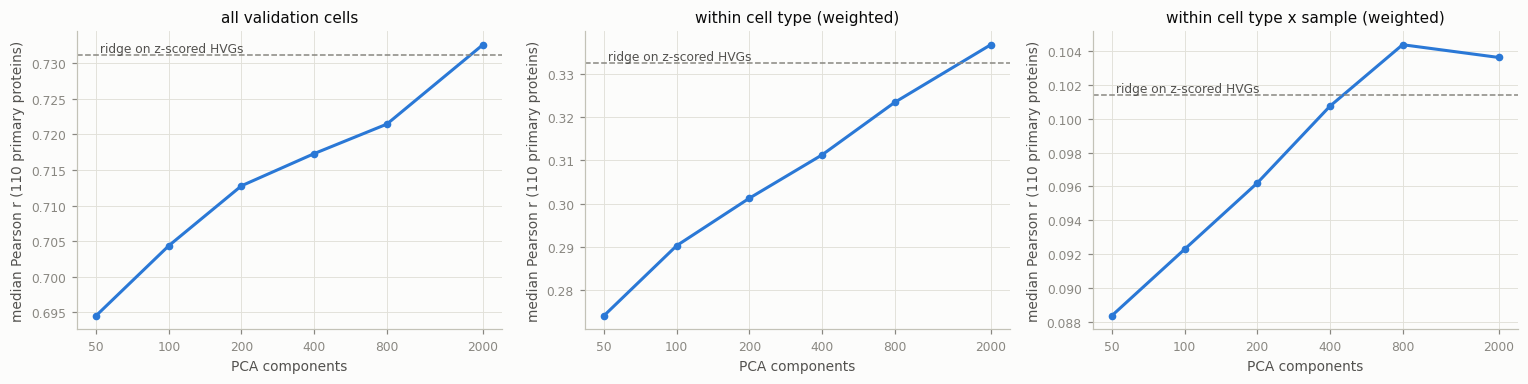

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, m, title in zip(axes, ["pearson_all", "within_w", "within_type_sample_w"],
                        ["all validation cells", "within cell type (weighted)", "within cell type x sample (weighted)"]):
    ax.plot(curve["n_pcs"], curve[m], color=P.BLUE, lw=2, marker="o", ms=4, label="ridge on PCA")
    ax.axhline(e_h[m].median(), color=P.MUTED, ls="--", lw=1)
    ax.text(curve["n_pcs"].iloc[0], e_h[m].median(), " ridge on z-scored HVGs", va="bottom", fontsize=8, color=P.INK_2)
    ax.set_xscale("log"); ax.set_xticks(curve["n_pcs"], [str(int(n)) for n in curve["n_pcs"]])
    ax.minorticks_off()
    ax.set_xlabel("PCA components"); ax.set_ylabel("median Pearson r (110 primary proteins)")
    ax.set_title(title)
fig.tight_layout()
fig.savefig(OUT_FIG / "phase3b_pcs_curve.png")
for m in ["pearson_all", "within_w", "within_type_sample_w"]:
    print(f"{m:<22} 50 PCs reach {curve[m].iloc[0] / curve[m].iloc[-1]:.0%} of the full-rank value")

## 3. Same cells for both metrics

Only cells in type x sample groups with >= 50 validation cells are kept. Cell types are then formed from
these same cells (again >= 50 cells).

In [6]:
def compare(cells, g_coarse, g_fine, label_coarse, label_fine):
    rows = []
    for m, p in pred.items():
        if m.startswith("cell-type mean"):
            continue
        e_c = evaluate(Y_va[cells], p[cells], g_coarse[cells], proteins, MIN_CELLS).loc[primary]
        e_f = evaluate(Y_va[cells], p[cells], g_fine[cells], proteins, MIN_CELLS).loc[primary]
        rows.append({"model": m, "cells": int(cells.sum()),
                     f"n {label_coarse}": int(e_c["n_types"].median()), f"n {label_fine}": int(e_f["n_types"].median()),
                     label_coarse: e_c["within_w"].median(), label_fine: e_f["within_w"].median()})
    out = pd.DataFrame(rows).set_index("model")
    out["difference"] = out[label_coarse] - out[label_fine]
    return out

ts_counts = pd.Series(ts_va).value_counts()
same_cells = np.isin(ts_va, ts_counts.index[ts_counts >= MIN_CELLS])
same_table = compare(same_cells, ct_va, ts_va, "within type", "within type x sample")
same_table

,cells,n within type,n within type x sample,within type,within type x sample,difference
model,,,,,,
own gene,8454,22,72,0.060,0.061,-0.001
ridge PCA (full rank),8454,22,72,0.328,0.104,0.224
ridge HVG,8454,22,72,0.324,0.101,0.222


## 4. donor1 only: within type vs. within type x site

donor1 is the only donor measured at all four sites. With the donor fixed, a drop from "within type" to
"within type x site" reflects the site effect, not donor differences. Shown for all validation donor1
cells and for the same-cells version.

In [7]:
site_va = d["obs_va"]["Site"].astype(str).to_numpy()
tsite_va = np.char.add(np.char.add(ct_va.astype(str), " | "), site_va.astype(str))
donor1 = (d["obs_va"]["DonorNumber"].astype(str) == "donor1").to_numpy()
print("donor1 validation cells:", donor1.sum())
d1_all = compare(donor1, ct_va, tsite_va, "within type", "within type x site")
tsc = pd.Series(tsite_va[donor1]).value_counts()
d1_same_cells = donor1 & np.isin(tsite_va, tsc.index[tsc >= MIN_CELLS])
d1_same = compare(d1_same_cells, ct_va, tsite_va, "within type", "within type x site")
pd.concat({"donor1, all cells": d1_all, "donor1, same cells": d1_same})

donor1 validation cells: 4635


cells  n within type  \
                   model                                         
donor1, all cells  own gene                4635             20   
                   ridge PCA (full rank)   4635             20   
                   ridge HVG               4635             20   
donor1, same cells own gene                2892             11   
                   ridge PCA (full rank)   2892             11   
                   ridge HVG               2892             11   

                                          n within type x site  within type  \
                   model                                                      
donor1, all cells  own gene                                 24        0.077   
                   ridge PCA (full rank)                    24        0.370   
                   ridge HVG                                24        0.358   
donor1, same cells own gene                                 24        0.067   
                   ridge PCA (full rank)                    24        0.335   
                   ridge HVG                                24        0.324   

                                          within type x site  difference  
                   model                                                  
donor1, all cells  own gene                            0.063       0.014  
                   ridge PCA (full rank)               0.096       0.274  
                   ridge HVG                           0.094       0.263  
donor1, same cells own gene                            0.063       0.004  
                   ridge PCA (full rank)               0.096       0.239  
                   ridge HVG                           0.094       0.230

In [8]:
if SUBSET is None:
    ts_table.to_csv(RESULTS_DIR / "phase3b_within_type_sample.csv")
    curve.to_csv(RESULTS_DIR / "phase3b_pcs_curve.csv", index=False)
    same_table.to_csv(RESULTS_DIR / "phase3b_same_cells.csv")
    pd.concat({"all_cells": d1_all, "same_cells": d1_same}, names=["subset"]).to_csv(RESULTS_DIR / "phase3b_donor1_site.csv")
import resource, platform
peak = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
print(f"peak memory: {(peak / 1e9 if platform.system() == 'Darwin' else peak * 1024 / 1e9):.2f} GB")

peak memory: 3.83 GB


## Findings (validation only)

Check: notebook 03's validation predictions are reproduced (max |diff| 2.4e-7).

**1. Within type vs. within type x sample** (medians over 110 primary proteins)

| Model | within type | within type x sample | difference |
|---|---|---|---|
| own gene, Phase 2 (all cells) | 0.072 | 0.062 | 0.01 |
| own gene, validation | 0.080 | 0.061 | 0.02 |
| ridge 3a (full-rank PCA), validation | 0.337 | 0.104 | 0.23 |
| **same cells** (8,454 cells, 22 types, 72 groups): own gene | 0.060 | 0.061 | 0.00 |
| **same cells**: ridge 3a | 0.328 | 0.104 | 0.22 |

On the same cells the result holds. About 0.23 of ridge's 0.34 within-type correlation lies between
samples within a cell type (technical and donor differences, which this design cannot separate), and about
0.10 is cell-to-cell variation inside a sample. The difference of two correlations is a heuristic split,
not an exact variance decomposition.

**2. donor1 only (donor fixed, four sites).** Ridge 3a: within type 0.37 -> within type x site 0.10
(same cells: 0.34 -> 0.10). Own gene: 0.08 -> 0.06. The donor is the same, so for donor1 most of the
between-sample component comes from **site**, i.e. it is technical. Whether ridge reaches this through a
site signature in RNA, or because site affects RNA and protein together, was not tested.

**3. PCA components.** Fraction of the full-rank value reached with 50 PCs: overall 95%, within type 81%,
within type x sample 85% (0.088 vs 0.104; flat from 800 PCs on). Truncation costs relatively more
within-type than overall information, also for the within-sample part.

Peak memory 3.8 GB.